In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Define feature columns for PCA (numerical features excluding user_id and risk_score)
pca_features = [col for col in num_cols if col not in ['user_id', 'risk_score']]

X_pca = df[pca_features]

# Standardize the features before applying PCA
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_pca)

# Initialize and fit PCA
pca = PCA()
pca.fit(X_scaled)

# Calculate explained variance metrics
exp_var_ratio = pca.explained_variance_ratio_
cum_exp_var = np.cumsum(exp_var_ratio)

# Print variance explained by each component
for i, ratio in enumerate(exp_var_ratio):
    print(f"Principal Component {i+1}: {ratio:.4f} ({cum_exp_var[i]:.4f} cumulative)")

Principal Component 1: 0.2051 (0.2051 cumulative)
Principal Component 2: 0.1142 (0.3193 cumulative)
Principal Component 3: 0.1073 (0.4266 cumulative)
Principal Component 4: 0.1021 (0.5286 cumulative)
Principal Component 5: 0.1001 (0.6287 cumulative)
Principal Component 6: 0.0987 (0.7274 cumulative)
Principal Component 7: 0.0952 (0.8226 cumulative)
Principal Component 8: 0.0903 (0.9129 cumulative)
Principal Component 9: 0.0865 (0.9994 cumulative)
Principal Component 10: 0.0006 (1.0000 cumulative)


Feature Loadings & Differences between PC1 and PC2:


,PC1,PC2,Abs_Difference
weight,0.602157,0.110938,0.491219
height,-0.373338,0.136271,0.509609
blood_glucose,0.036989,-0.371068,0.408056
physical_activity,0.031433,-0.345744,0.377177
diet,-0.061063,-0.361157,0.300094
medication_adherence,0.070589,-0.256322,0.326912
stress_level,-0.054731,0.116916,0.171647
sleep_hours,0.016045,0.530831,0.514786
hydration_level,0.042196,-0.468262,0.510458
bmi,0.694208,0.032190,0.662018


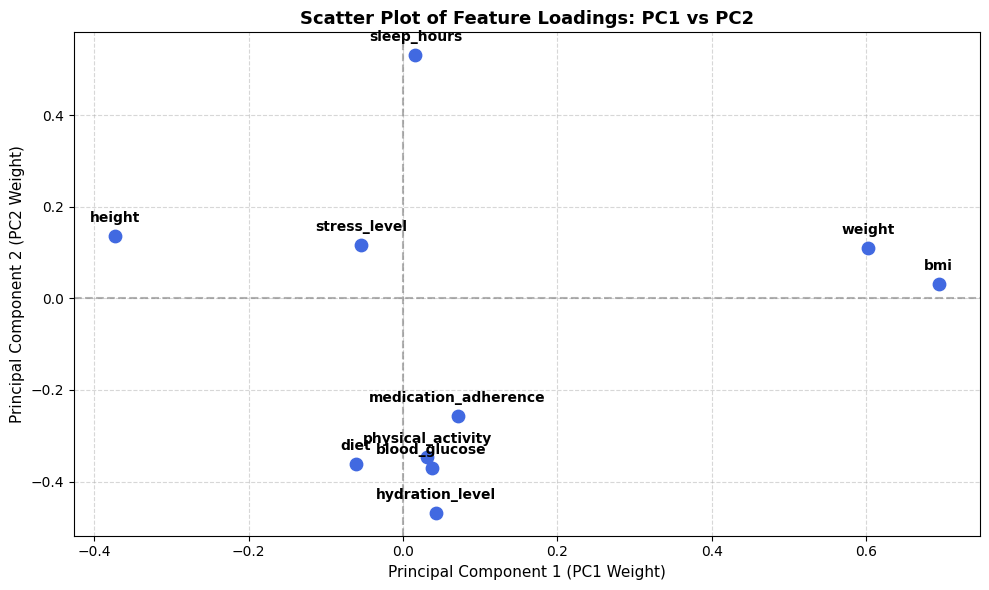

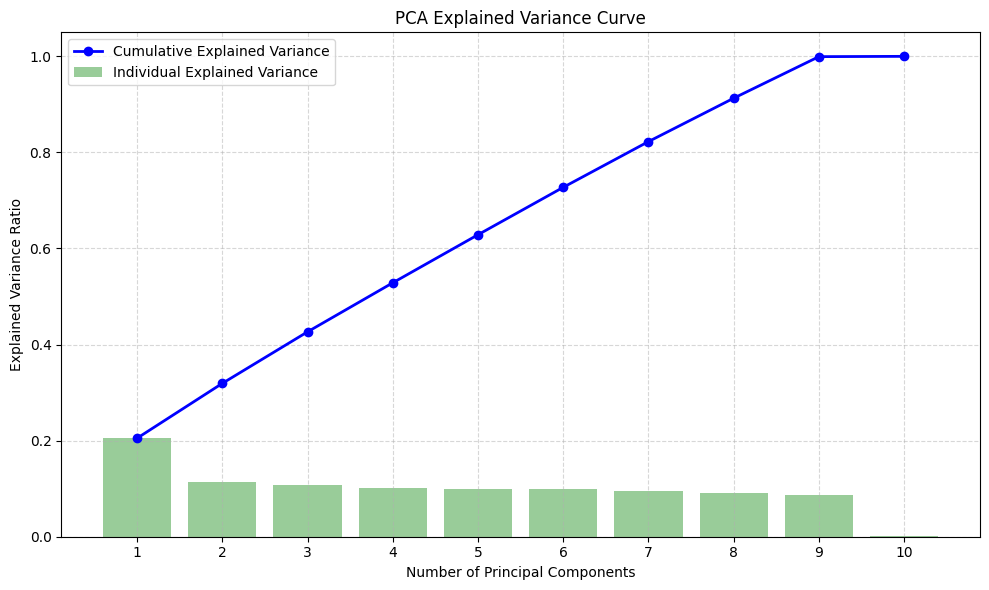

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Create a DataFrame for the PCA loadings
loadings_df = pd.DataFrame(
    pca.components_[:2],  # Get PC1 and PC2
    columns=pca_features,
    index=['PC1', 'PC2']
).T  # Transpose so features are rows

# Calculate the absolute difference in feature weights between PC1 and PC2
loadings_df['Abs_Difference'] = abs(loadings_df['PC1'] - loadings_df['PC2'])

# Display the feature weights and their differences side-by-side
print("Feature Loadings & Differences between PC1 and PC2:")
display(loadings_df)

# 2. Visualize using a Scatter Plot (PC1 vs PC2)
plt.figure(figsize=(10, 6))
plt.scatter(loadings_df['PC1'], loadings_df['PC2'], color='royalblue', s=80, zorder=3)

# Annotate each point with its feature name
for feature, row in loadings_df.iterrows():
    plt.annotate(
        feature,
        (row['PC1'], row['PC2']),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center',
        fontsize=10,
        fontweight='bold'
    )

# Add reference lines at 0
plt.axhline(0, color='grey', linestyle='--', alpha=0.6)
plt.axvline(0, color='grey', linestyle='--', alpha=0.6)

plt.xlabel('Principal Component 1 (PC1 Weight)', fontsize=11)
plt.ylabel('Principal Component 2 (PC2 Weight)', fontsize=11)
plt.title('Scatter Plot of Feature Loadings: PC1 vs PC2', fontsize=13, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Visualize the explained variance as a curve line graph
plt.figure(figsize=(10, 6))

# Line plot with markers for cumulative explained variance
plt.plot(range(1, len(cum_exp_var) + 1), cum_exp_var, marker='o', linestyle='-', color='b', linewidth=2, label='Cumulative Explained Variance')

# Bar plot for individual explained variance for reference
plt.bar(range(1, len(exp_var_ratio) + 1), exp_var_ratio, alpha=0.4, align='center', color='g', label='Individual Explained Variance')

plt.ylabel('Explained Variance Ratio')
plt.xlabel('Number of Principal Components')
plt.title('PCA Explained Variance Curve')
plt.xticks(range(1, len(exp_var_ratio) + 1))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='best')
plt.tight_layout()
plt.show()